# 17 - Snapshot augmentation and player decisions (experiment 09)

Experiments 05-08 showed that adding or removing features of the turn-30 state does not move the CV (≈ 0.68). Of
the ideas still open (see `EXPERIMENTS.md`, "Idee da provare"), this notebook tests the two with the highest
priority.

**P4: snapshot augmentation (first priority).** The learning curve of experiment 05 is still rising, and external
data is not allowed. Every training battle can also be cut at an earlier turn (22, 24, 26, 28): the features of the
battle seen for only *t* turns are a real, slightly noisier example of "state → winner" with the same label. These rows
are added to the **training part of each fold only**, with a lower `sample_weight` and a `snapshot_turn` column;
validation always uses the turn-30 rows. All the snapshots of a battle follow the battle into its fold, so nothing
leaks (it is a group split by `battle_id`).

**P1: player decision quality (second priority).** All current features describe the battle state; these describe
the players: type effectiveness of the attacks they choose against the Pokémon actually hit, status moves wasted on a
target already statused or immune, and how the Pokémon they switch in fare against the opponent's attack of that turn.
Player skill carries on into the turns we do not see, where most errors are (62% in open battles).

| Section | Content |
|---|---|
| 1 | Check: the refactored code (`n_turns` parameter) rebuilds exactly the v1 features at turn 30 |
| 2 | Snapshots at turns 22-28 (descriptive) |
| 3 | P1: decision-quality features, descriptive + paired CV |
| 4 | P4: snapshot augmentation, paired CV for several weights |
| 5 | P4 + P1 together |
| 6 | Summary table, decision, stress test |

Comparisons are **paired**: every configuration is scored on the same 15 folds (seeds 42 / 7 / 123 × 5) as the
baseline, with the tuned LightGBM (and LogReg) of experiment 04.

**Decision rule (fixed before running):** a configuration is adopted if it gains **≥ +0.5 points** and improves
**at least 11 of the 15 folds**.

The move-damage table used by `exp_dmg_*` was estimated on the whole train in notebook 02, exactly as for the v1
features (it does not use the target).

## 0. Setup

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import find_data_dir, load_type_chart
from src.features import build_features_at, decision_quality_features, robust_columns
from src.models import get_model_specs, with_params
from src.validation import REPEAT_SEEDS, SEED, augmented_cv_scores, perturb_p2_ko

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 250)
PROC = ROOT / "data" / "processed"
OUT = PROC / "models"
OUT.mkdir(parents=True, exist_ok=True)

team, timeline, states = [pd.read_pickle(PROC / f"{name}_train.pkl") for name in ("team", "timeline", "states")]
species = pd.read_pickle(PROC / "species_table.pkl")          # built from train only
type_chart = load_type_chart(find_data_dir() / "type_chart_gen2.csv")

ref = pd.read_pickle(PROC / "features_train.pkl")             # v1 features (notebook 03)
with open(PROC / "feature_groups.json") as f:
    groups = json.load(f)
CAT = groups["species_cat"]
NUM = [c for c in ref.columns if c not in CAT + ["player_won"]]
print(f"battles: {ref.shape[0]:,} | v1 features: {len(NUM)}")

specs = get_model_specs()
MODELS = {
    "lightgbm": with_params(specs["lightgbm"], {
        "model__colsample_bytree": 0.6286197472598067, "model__learning_rate": 0.006552992991573526,
        "model__min_child_samples": 106, "model__n_estimators": 1424, "model__num_leaves": 12,
        "model__reg_alpha": 0.6070874110546393, "model__reg_lambda": 2.7129089558470034,
        "model__subsample": 0.6629794526009424}),
    "logreg": with_params(specs["logreg"], {"model__C": 0.006690421166498805}),
}

battles: 10,000 | v1 features: 155


## 1. Check: the v1 features at turn 30 are unchanged

`build_features_at` truncates the timeline, replays the Pokémon states and builds the features with `n_turns` as a
parameter. At 30 turns it must give exactly the features of notebook 03, otherwise the comparison below is not valid.

In [2]:
t0 = time.time()
full30, groups30 = build_features_at(team, timeline, species, type_chart, 30, decision_quality=True)
print(f"built in {time.time() - t0:.0f}s")

check = full30[ref.columns]
max_diff = (check[NUM].astype(float) - ref[NUM].astype(float)).abs().max().max()
nan_mismatch = int((check[NUM].isna() != ref[NUM].isna()).sum().sum())
cat_equal = bool((check[CAT].fillna("") == ref[CAT].fillna("")).all().all())
same_order = bool((check.index == ref.index).all())
print(f"max |difference|: {max_diff:.2e} | NaN mismatches: {nan_mismatch} | categorical equal: {cat_equal} | same order: {same_order}")
assert max_diff < 1e-9 and nan_mismatch == 0 and cat_equal and same_order, "v1 features changed"

y = full30["player_won"]
DQ = groups30["decision_quality"]
X30 = full30[NUM + DQ]
print(f"decision-quality features: {len(DQ)}")

built in 7s
max |difference|: 0.00e+00 | NaN mismatches: 0 | categorical equal: True | same order: True
decision-quality features: 24


## 2. Snapshots of the training battles

The same battles cut after 22, 24, 26 and 28 turns. Trend features are counted back from the last turn
(`trend_hp_diff_t25` = 5 turns before the end), so they mean the same thing at every snapshot.

In [3]:
SNAPSHOTS = [22, 24, 26, 28]
snaps = {30: X30.assign(snapshot_turn=30)}
t0 = time.time()
for t in SNAPSHOTS:
    f_t, _ = build_features_at(team, timeline, species, type_chart, t, decision_quality=True)
    assert (f_t.index == X30.index).all()
    snaps[t] = f_t[NUM + DQ].assign(snapshot_turn=t)
    print(f"turn {t}: built ({time.time() - t0:.0f}s)")

pd.to_pickle(snaps, PROC / "snapshots_train.pkl")
# How much of the outcome each snapshot already shows: correlation of the main features with the winner
desc = pd.DataFrame({t: {f: snaps[t][f].corr(y) for f in ["diff_hp_total", "diff_lost_est", "diff_statused"]}
                     for t in sorted(snaps)}).T
desc.index.name = "snapshot turn"
desc.round(3)

turn 22: built (7s)
turn 24: built (14s)
turn 26: built (21s)
turn 28: built (28s)


,diff_hp_total,diff_lost_est,diff_statused
snapshot turn,,,
22,0.276,-0.243,-0.071
24,0.302,-0.268,-0.076
26,0.327,-0.291,-0.088
28,0.348,-0.317,-0.090
30,0.374,-0.345,-0.084


## 3. P1: decision-quality features

Per side (and `diff_*`): mean type effectiveness of the attacks against the Pokémon actually hit, share of
super-effective and of resisted / immune attacks, attacks into an immunity, status moves wasted (target already
statused or immune by the type chart), and for voluntary switches the effectiveness of the opponent's attack of that
turn against the Pokémon switched in. Hidden Power is skipped (its recorded type is always normal). None of them uses
KOs, so they all stay in the robust subset.

In [4]:
print("all in the robust subset:", set(robust_columns(DQ)) == set(DQ))
summary_dq = pd.DataFrame({"mean": X30[DQ].mean(), "share of NaN": X30[DQ].isna().mean(),
                           "corr with winner": X30[DQ].corrwith(y)})
summary_dq.round(3)

all in the robust subset: True


,mean,share of NaN,corr with winner
p1_dq_mean_eff,1.023,0.003,0.029
p2_dq_mean_eff,1.054,0.002,-0.098
p1_dq_frac_se,0.163,0.003,0.014
p2_dq_frac_se,0.182,0.002,-0.063
p1_dq_frac_resisted,0.244,0.003,-0.029
p2_dq_frac_resisted,0.232,0.002,0.071
p1_dq_n_immune_hits,0.730,0.000,-0.022
p2_dq_n_immune_hits,0.693,0.000,0.038
p1_dq_wasted_status,0.253,0.000,-0.002
p2_dq_wasted_status,0.234,0.000,0.022


In [5]:
# Optional pre-screen: Pearson correlation with the residual of the out-of-fold LightGBM of notebook 08
oof_path = PROC / "oof_lgbm.pkl"
if oof_path.exists():
    residual = pd.read_pickle(oof_path)["residual"].reindex(X30.index)
    print("noise level for 10,000 battles: |r| ~ 0.02")
    display(X30[DQ].corrwith(residual).sort_values(key=abs, ascending=False).round(3).to_frame("corr with residual"))
else:
    print("oof_lgbm.pkl not found: run notebooks/08_error_analysis.ipynb first (optional)")

noise level for 10,000 battles: |r| ~ 0.02


,corr with residual
diff_dq_frac_resisted,-0.039
diff_dq_switch_mean_eff,-0.036
diff_dq_mean_eff,0.035
p2_dq_switch_mean_eff,0.035
diff_dq_switch_frac_resisted,0.034
p1_dq_frac_resisted,-0.032
p2_dq_switch_frac_resisted,-0.028
p1_dq_mean_eff,0.026
p2_dq_n_switch_into_se,0.024
p2_dq_frac_wasted_status,0.023


In [6]:
# Paired repeated CV: every configuration on the same 15 folds as the baseline
score_cache = {}

def scores(key, model, X_, extra=()):
    if key not in score_cache:
        score_cache[key] = np.concatenate([augmented_cv_scores(model, X_, y, extra, seed=s) for s in REPEAT_SEEDS])
    return score_cache[key]

results = []

def compare(model_name, config, X_, extra=(), n_extra_rows=0):
    base = scores((model_name, "v1"), MODELS[model_name], X30[NUM])
    cand = scores((model_name, config), MODELS[model_name], X_, extra)
    d = cand - base
    row = {"model": model_name, "config": config, "n_features": X_.shape[1], "extra rows": n_extra_rows,
           "mean": cand.mean(), "std": cand.std(), "baseline": base.mean(), "gain (points)": d.mean() * 100,
           "std of gain": d.std() * 100, "folds improved": int((d > 0).sum())}
    results.append(row)
    print(f"{model_name:8s} {config:28s}: {row['mean']:.4f} (gain {row['gain (points)']:+.2f} ± {row['std of gain']:.2f}, "
          f"{row['folds improved']}/15 folds)")
    return row

t0 = time.time()
for m in MODELS:
    compare(m, "v1", X30[NUM])
    compare(m, "v1 + decisions", X30[NUM + DQ])
print(f"done in {time.time() - t0:.0f}s")

lightgbm v1                          : 0.6779 (gain +0.00 ± 0.00, 0/15 folds)
lightgbm v1 + decisions              : 0.6773 (gain -0.06 ± 0.57, 7/15 folds)
logreg   v1                          : 0.6750 (gain +0.00 ± 0.00, 0/15 folds)
logreg   v1 + decisions              : 0.6734 (gain -0.16 ± 0.45, 2/15 folds)
done in 28s


## 4. P4: snapshot augmentation

Training part of each fold = its turn-30 rows (weight 1) + the snapshot rows of the same battles. Configurations
(LightGBM, v1 features + `snapshot_turn`):
- turns 26 and 28, weight 0.5;
- turns 22-28, weight 0.5;
- turns 22-28, weight 1 (all rows equal);
- turns 22-28, weight growing with the turn: (t - 20) / 10, i.e. 0.2 / 0.4 / 0.6 / 0.8.

The best configuration is then also tried with the LogReg.

In [7]:
def extra_rows(turns, weight, cols):
    # weight: a number, or a function of the snapshot turn
    return [(snaps[t][cols], weight(t) if callable(weight) else weight) for t in turns]

COLS = NUM + ["snapshot_turn"]
P4_CONFIGS = {
    "snap 26-28, w 0.5": ([26, 28], 0.5),
    "snap 22-28, w 0.5": ([22, 24, 26, 28], 0.5),
    "snap 22-28, w 1": ([22, 24, 26, 28], 1.0),
    "snap 22-28, w ramp": ([22, 24, 26, 28], lambda t: (t - 20) / 10),
}
t0 = time.time()
for name, (turns, w) in P4_CONFIGS.items():
    compare("lightgbm", name, snaps[30][COLS], extra_rows(turns, w, COLS), n_extra_rows=len(turns) * len(y))
print(f"done in {time.time() - t0:.0f}s")

p4 = pd.DataFrame([r for r in results if r["config"] in P4_CONFIGS]).sort_values("mean", ascending=False)
best_p4 = p4.iloc[0]["config"]
print(f"best snapshot configuration: {best_p4}")
turns, w = P4_CONFIGS[best_p4]
compare("logreg", best_p4, snaps[30][COLS], extra_rows(turns, w, COLS), n_extra_rows=len(turns) * len(y))

lightgbm snap 26-28, w 0.5           : 0.6768 (gain -0.11 ± 0.50, 6/15 folds)
lightgbm snap 22-28, w 0.5           : 0.6786 (gain +0.07 ± 0.59, 10/15 folds)
lightgbm snap 22-28, w 1             : 0.6774 (gain -0.05 ± 0.68, 4/15 folds)
lightgbm snap 22-28, w ramp          : 0.6781 (gain +0.02 ± 0.52, 6/15 folds)
done in 122s
best snapshot configuration: snap 22-28, w 0.5
logreg   snap 22-28, w 0.5           : 0.6737 (gain -0.13 ± 0.36, 5/15 folds)


{'model': 'logreg',
 'config': 'snap 22-28, w 0.5',
 'n_features': 156,
 'extra rows': 40000,
 'mean': np.float64(0.6736666666666667),
 'std': np.float64(0.008137703743822463),
 'baseline': np.float64(0.6749999999999999),
 'gain (points)': np.float64(-0.13333333333333347),
 'std of gain': np.float64(0.358081306719888),
 'folds improved': 5}

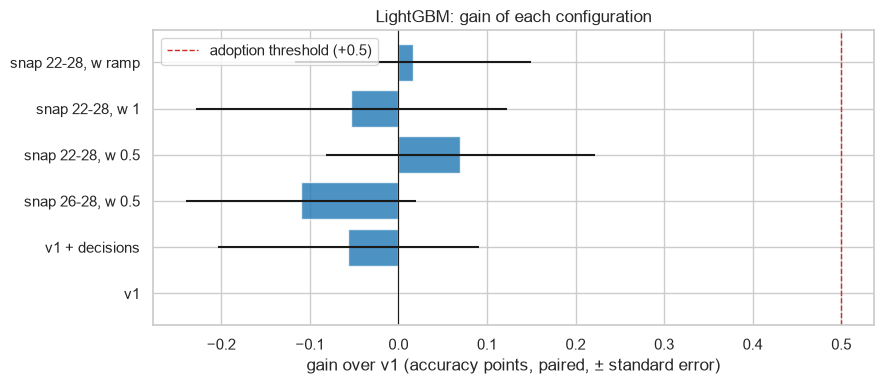

In [8]:
res = pd.DataFrame(results)
d = res[res["model"] == "lightgbm"].set_index("config")
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(d.index, d["gain (points)"], xerr=d["std of gain"] / np.sqrt(15), color="tab:blue", alpha=0.8)
ax.axvline(0, c="k", lw=0.8)
ax.axvline(0.5, c="tab:red", ls="--", lw=1, label="adoption threshold (+0.5)")
ax.set_xlabel("gain over v1 (accuracy points, paired, ± standard error)")
ax.set_title("LightGBM: gain of each configuration")
ax.legend()
plt.tight_layout()
plt.show()

## 5. P4 + P1 together

In [9]:
COLS_DQ = NUM + DQ + ["snapshot_turn"]
turns, w = P4_CONFIGS[best_p4]
t0 = time.time()
compare("lightgbm", f"{best_p4} + decisions", snaps[30][COLS_DQ], extra_rows(turns, w, COLS_DQ),
        n_extra_rows=len(turns) * len(y))
print(f"done in {time.time() - t0:.0f}s")

lightgbm snap 22-28, w 0.5 + decisions: 0.6761 (gain -0.18 ± 0.45, 5/15 folds)
done in 39s


## 6. Summary table and decision

Rule fixed before running: adopt if the gain is **≥ +0.5 points** and at least **11 of 15 folds** improve.

In [10]:
summary = pd.DataFrame(results).drop_duplicates(["model", "config"])
summary["adopt"] = (summary["gain (points)"] >= 0.5) & (summary["folds improved"] >= 11)
summary = summary.sort_values(["model", "mean"], ascending=[True, False])
summary.to_csv(OUT / "snapshots_decisions.csv", index=False)
summary.round(4)

,model,config,n_features,extra rows,mean,std,baseline,gain (points),std of gain,folds improved,adopt
5,lightgbm,"snap 22-28, w 0.5",156,40000,0.6786,0.0098,0.6779,0.0700,0.5899,10,False
7,lightgbm,"snap 22-28, w ramp",156,40000,0.6781,0.0097,0.6779,0.0167,0.5160,6,False
0,lightgbm,v1,155,0,0.6779,0.0097,0.6779,0.0000,0.0000,0,False
6,lightgbm,"snap 22-28, w 1",156,40000,0.6774,0.0100,0.6779,-0.0533,0.6796,4,False
1,lightgbm,v1 + decisions,179,0,0.6773,0.0072,0.6779,-0.0567,0.5698,7,False
4,lightgbm,"snap 26-28, w 0.5",156,20000,0.6768,0.0107,0.6779,-0.1100,0.5031,6,False
9,lightgbm,"snap 22-28, w 0.5 + decisions",180,40000,0.6761,0.0092,0.6779,-0.1767,0.4520,5,False
2,logreg,v1,155,0,0.6750,0.0098,0.6750,0.0000,0.0000,0,False
8,logreg,"snap 22-28, w 0.5",156,40000,0.6737,0.0081,0.6750,-0.1333,0.3581,5,False
3,logreg,v1 + decisions,179,0,0.6734,0.0084,0.6750,-0.1567,0.4483,2,False


In [11]:
# Stress test of the best LightGBM configuration (seed-42 folds): P2's KO recording perturbed in validation only
lgbm = summary[(summary["model"] == "lightgbm") & (summary["config"] != "v1")]
best = lgbm.iloc[0]["config"]
print(f"best LightGBM configuration: {best}")

def setup(config):
    if config == "v1":
        return X30[NUM], ()
    if config == "v1 + decisions":
        return X30[NUM + DQ], ()
    cols = COLS_DQ if config.endswith("+ decisions") else COLS
    turns, w = P4_CONFIGS[config.replace(" + decisions", "")]
    return snaps[30][cols], extra_rows(turns, w, cols)

rows = {}
for config in ["v1", best]:
    X_, extra = setup(config)
    r = {"clean": augmented_cv_scores(MODELS["lightgbm"], X_, y, extra, seed=SEED).mean()}
    for f in (0.5, 1.0):
        r[f"p2_ko_fixed_{f:g}"] = augmented_cv_scores(MODELS["lightgbm"], X_, y, extra, seed=SEED,
                                                      val_transform=lambda v, f=f: perturb_p2_ko(v, f, SEED)).mean()
    rows[config] = r
stress = pd.DataFrame(rows).T
stress["drop (points)"] = (stress["clean"] - stress[["p2_ko_fixed_0.5", "p2_ko_fixed_1"]].min(axis=1)) * 100
stress.round(4)

best LightGBM configuration: snap 22-28, w 0.5


,clean,p2_ko_fixed_0.5,p2_ko_fixed_1,drop (points)
v1,0.6798,0.6794,0.6794,0.04
"snap 22-28, w 0.5",0.6805,0.6792,0.6794,0.13


## 7. Summary

- **Check (section 1):** the refactored code rebuilds the v1 features at turn 30 exactly (max difference 0, no NaN
  mismatch), so the comparisons are valid.
- **Snapshots (section 2):** the signal grows steadily with the turn (correlation of `diff_hp_total` with the winner
  0.28 at turn 22, 0.37 at turn 30): the earlier snapshots are real but noisier examples.
- **P1, decision quality (section 3):** 24 features, all robust. They correlate a little with the winner (up to
  |r| = 0.10 for `diff_dq_mean_eff`) and with the residual of the v1 model (|r| up to 0.04, above the noise of ~0.02),
  but in paired CV they do not help: LightGBM -0.06 points (7/15 folds), LogReg -0.16 (2/15). Same pattern as
  experiment 06: a bit of new information, too small to change the predictions.
- **P4, snapshot augmentation (section 4):** best configuration turns 22-28 with weight 0.5, +0.07 ± 0.59 points
  (10/15 folds); the other weights go from -0.11 to +0.02. More rows of the same battles do not add information: the
  snapshots are strongly correlated with the turn-30 row. LogReg -0.13.
- **P4 + P1 (section 5):** -0.18 points.
- **Stress test:** drop 0.13 points (v1: 0.04), negligible.

**Decision:** no configuration reaches the rule (≥ +0.5 points and ≥ 11/15 folds). Both ideas are negative/neutral;
the v1 features with the experiment-04 models stay the reference. The code stays in `src/` (default off), the results
in `data/processed/models/snapshots_decisions.csv`.